# Document extraction cascade

**Recipe 39** · Level 3 (Intermediate) · Decision type: `Choice` + `Noul`

Select candidate values for document fields, verify each selection against its source span, and route uncertain or inconsistent records to review.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

A two-stage cascade over a short purchase document with two fields, `invoice_number` and `total_amount`. Stage 1 is a `Choice` per field: which candidate span, if any, states that field's value, drawn from a fixed set Python extracts from the document text, plus a shared `not_found` fallback. Stage 2 is a `Noul` per field: does the span stage 1 picked really state that field, as opposed to a related but different figure (a purchase order number, a subtotal, a previous balance)? By the end you will have seen both typed answers for one document, the rule that composes them into one field result and then one document result, and an evaluation at both levels: per field, and per document.


The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays stored answers offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls and changes nothing else. The header states which mode ran, and every number below carries that mode with it. `get_backend` is called exactly once, here, for the whole notebook: every request below reuses this one `backend`. Every document's own cascade is decided once and cached by id, through the `decide()` wrapper defined below, so a document shown individually and later scored (or shown more than once) issues no second request for it.


In [ ]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    evaluate_outcomes,
    noul_confidence,
    select_confidence_threshold,
    select_threshold,
    selective_curve,
    threshold_sweep,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import (
    apply_style,
    plot_answer_probabilities,
    plot_risk_coverage,
    plot_threshold_sweep,
    run_header,
    show_answer,
)

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())  # the one backend this notebook uses

# Every call to backend.decide is counted here, independent of the cache below: a count that
# only reported how many distinct documents were cached could not catch a document's cascade
# being decided twice ("How many requests this run made" prints the total).
decide_calls = [0]
_raw_decide = backend.decide


def _counted_decide(state, questions):
    decide_calls[0] += 1
    return _raw_decide(state, questions)


backend.decide = _counted_decide

# Every document's cascade is decided once and cached by id: a document shown individually
# (the demo cells, the flip comparison below) and later scored as part of its split issues no
# second request for it.
decided = {}


def decide(example):
    return helpers.decide_document_cached(backend, decided, example.id, example.fields)


# scored excludes the two demo examples: they carry no gold label, so no metric below is
# about them. Each scored example is one document; each document has two fields, so the
# field-level metrics later cover twice as many (document, field) pairs as there are
# documents here -- examples and units are different quantities, both reported below.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step, not a
# result. This label does not depend on the run mode, unlike `check` above.
selection = " (a selection step, not a reported result)"

run_header(
    39,
    "Document extraction cascade",
    backend=backend,
    n_examples=len(scored),
)

## The state

Python extracts the candidate spans before Jev ever sees the document: `helpers.extract_candidates` splits the document into sentences and keeps the ones that look like they could name a field (a reference-shaped number for `invoice_number`, a dollar amount for `total_amount`). The state for a stage-1 request is exactly those candidate spans, by id, for the fields that have at least one -- never the full document, and never an offset Jev would have to resolve itself.


In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
document = demo["d01-both-fields"]
print("Python has:")
print(json.dumps(document.fields, indent=2))
s1_fields = helpers.stage1_fields(document.fields)
state1 = helpers.build_stage1_state(document.fields, s1_fields)
print("Jev sees, in the stage-1 request:")
print(json.dumps(state1, indent=2))

Python has:
{
  "doc_id": "F01",
  "document": "Purchase Confirmation #F01. Invoice #7001 for your records. Bill To: Keystone Retail Group, 400 Commerce Ave. Total due: $128.00. Items: a box of plywood sheets. Thank you for your business."
}
Jev sees, in the stage-1 request:
{
  "invoice_number": {
    "s1": "Invoice #7001 for your records. "
  },
  "total_amount": {
    "s1": "Total due: $128.00. "
  }
}


## The questions

Stage 1 asks one `Choice` per field that has a candidate: which span, if any, states this field, with the shared `not_found` option added by Python for a document where none of them does. The two fields' `Choice` questions never depend on each other, so they travel together in one request.

Stage 2 asks one `Noul` per field stage 1 named a real candidate for: a statement that can be true or false, "the selected text really states this field". A field's own `Noul` instructions are fixed text; the candidate text being verified lives in the *state*, not the instructions, so the question itself never changes from one document to the next -- only what it is asked about does. A field stage 1 resolved to `not_found` is never verified at all: there is no text to check.


In [3]:
questions1 = helpers.build_stage1_questions(document.fields, s1_fields)
for name, question in questions1.items():
    print(name, question.to_dict())

invoice_number {'type': 'choice', 'instructions': "Which one of the candidate spans below, if any, states this document's own invoice number -- not a purchase order number, a tracking number, or a reference to a previous invoice? Choose 'not_found' if none of them does.", 'criteria': {'s1': None, 'not_found': "None of the candidate spans above states this document's own invoice number: the document may instead name a purchase order, a tracking number, a reference to a previous invoice, or no number of this kind at all."}}
total_amount {'type': 'choice', 'instructions': "Which one of the candidate spans below, if any, states the total amount due on this document -- not a subtotal, a tax or shipping line, or a previous balance? Choose 'not_found' if none of them does.", 'criteria': {'s1': None, 'not_found': 'None of the candidate spans above states the total amount due on this document: the document may instead show only a subtotal, a tax or shipping line, a previous balance, or no dolla

### The request boundary

A question that depends on an earlier answer goes in a later request; independent questions share one. Stage 2's own questions are built from stage 1's answers (`helpers.stage2_fields`, `helpers.build_stage2_state`), so stage 2 can never be sent before stage 1 returns -- but the two fields' stage-2 propositions still do not depend on *each other*, so whenever more than one field reaches stage 2, both travel together in the same, later, request. `helpers.plan_requests` makes this boundary a value the notebook can print, not only a rule to take on faith: it names which fields are bundled into which request, and which, if any, request it depended on.

Three documents below show the three shapes this takes: `d01-both-fields` makes two requests, each bundling both fields; `d02-no-candidates` makes none, because neither field has a candidate at all; `t07` makes two requests but the second bundles only one field, because `invoice_number`'s own stage-1 answer named `not_found` (a decoy tracking number was present, but nothing stated the invoice number) while `total_amount`'s named a real candidate.


In [ ]:
for doc_id in ("d01-both-fields", "d02-no-candidates", "t07"):
    example = next(e for e in examples if e.id == doc_id)
    s1, a1, s2, a2 = decide(example)
    plan = helpers.plan_requests(s1, s2)
    print(f"{doc_id}:")
    if not plan:
        print("  no request: neither field has a candidate")
    for request in plan:
        depends = (
            f", depends on stage-{request.stage - 1}'s answer for {request.depends_on}"
            if request.depends_on
            else ""
        )
        print(f"  request (stage {request.stage}): fields {request.fields}{depends}")

## One answer up close

`d01-both-fields` has a real candidate for each field, so it makes both requests. The stage-1 `Choice` answer names a span and carries a `confidence` for it; the stage-2 `Noul` answer is a single probability that the selection really states the field, with no confidence of its own -- `noul_confidence` (`|2p - 1|`) derives one, usable the same way a `Choice` or `Score` confidence is.


In [ ]:
s1, stage1_answers, s2, stage2_answers = decide(document)
for field in helpers.FIELDS:
    print(f"-- {field} --")
    show_answer(stage1_answers[field])
    if field in stage2_answers:
        show_answer(stage2_answers[field])
        print(f"  noul_confidence: {noul_confidence([stage2_answers[field].noul])[0]:.2f}")

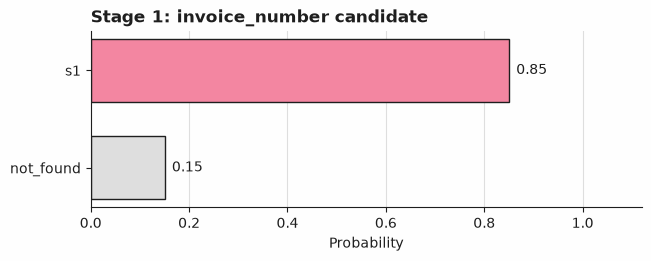

In [6]:
plot_answer_probabilities(
    stage1_answers["invoice_number"], title="Stage 1: invoice_number candidate"
)

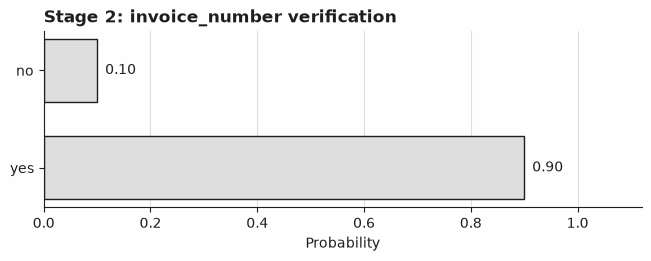

In [7]:
plot_answer_probabilities(
    stage2_answers["invoice_number"], title="Stage 2: invoice_number verification"
)

## Python's part

Three checks, in this order, decide one field's result once stage 2 has answered: a defensive check that the choice really names one of this document's own candidates; then the model's own uncertainty (`noul_confidence` below the frozen [confidence gate](../../docs/glossary.md#confidence-gate) sends the field to [review](../../docs/glossary.md#review) as **uncertain**); then the verification itself (`noul` below the frozen [business threshold](../../docs/glossary.md#business-threshold) sends it to review as **inconsistent**). At the values this notebook freezes, the gate names which of those two reasons a review carries; it never changes which fields are withheld, because every answer that clears the business threshold already clears the gate too -- 'Evaluation' below proves this by sweep and by removing the gate outright, and explains why. A field whose stage-1 answer is `not_found` is reported as `not_found` directly, whatever its confidence -- it is a complete answer, not a deferral, records no action, and being wrong leaves nothing standing beyond the missed field itself (`CONTRIBUTING.md` section 4's three-part test). A field with no candidate at all is resolved the same way, before any question is ever built.

The document is composed from its own two fields: `accepted` only when neither field was sent to review. Applying this to both documents above shows both outcomes: `d01-both-fields` has nothing to review and so is accepted; `d02-no-candidates` resolves both fields to `not_found` directly, with zero requests, and is accepted too, since `not_found` is itself a complete answer when nothing supports the field. A document in `fixtures/` with a real field in review (`v04`, `v06`, `t08`, ...) is composed as not accepted.


In [ ]:
# The two settings this rule needs (the confidence gate and the business threshold) are
# chosen on validation in "Evaluation" below; frozen here with their already-chosen values so
# this section can show the rule before the selection story. (The two numbers are not
# hand-picked: they are exactly what the Evaluation section's own selection cells compute.)
demo_business_threshold = 0.85
demo_confidence_gate = 0.70

for doc_id in ("d01-both-fields", "d02-no-candidates"):
    example = next(e for e in examples if e.id == doc_id)
    s1, a1, s2, a2 = decide(example)
    results = {
        field: helpers.field_result(
            doc_id, field, example.fields, a1, a2, demo_business_threshold, demo_confidence_gate
        )
        for field in helpers.FIELDS
    }
    for field, result in results.items():
        print(f"{doc_id}/{field}: {result.outcome} ({result.reason})")
    outcome = helpers.compose_document_outcome(doc_id, results)
    print(f"{doc_id}: accepted={outcome.accepted}")

### Why both fields, and both stages, matter

Flipping one field's stage-1 choice, or one field's stage-2 verification, on a real document already in `fixtures/`, changes what the rule reports -- neither field and neither stage is along for the ride. `v11` has three candidate spans for `invoice_number` (two decoys, one real); naming a decoy instead of the real one, with its own stage-2 verification left exactly as it is, turns a correct field into a wrong one. `v01` is fully accepted as committed; flipping only its `invoice_number` verification from confidently-true to confidently-false, with its stage-1 choice left exactly as it is, sends that field to review and withholds the whole document.


In [ ]:
v11_example = next(e for e in examples if e.id == "v11")
_s1, v11_a1, _s2, v11_a2 = decide(v11_example)
v11_spans = helpers.spans_by_id(v11_example.fields, "invoice_number")
real_choice = next(sid for sid, text in v11_spans.items() if "5126" in text)
decoy_choice = next(sid for sid in v11_spans if sid != real_choice)
v11_noul = v11_a2["invoice_number"].noul
v11_confidence = noul_confidence([v11_noul])[0]
real = helpers.finalize_field(
    "v11", "invoice_number", real_choice, v11_spans, v11_noul, v11_confidence, 0.85, 0.70
)
decoy = helpers.finalize_field(
    "v11", "invoice_number", decoy_choice, v11_spans, v11_noul, v11_confidence, 0.85, 0.70
)
print(
    f"v11/invoice_number, real choice:  outcome={real.outcome}, correct={helpers.matches_gold(real, '5126')}"
)
print(
    f"v11/invoice_number, decoy choice: outcome={decoy.outcome}, correct={helpers.matches_gold(decoy, '5126')}"
)

v01_example = next(e for e in examples if e.id == "v01")
_s1, v01_a1, _s2, v01_a2 = decide(v01_example)
v01_spans = helpers.spans_by_id(v01_example.fields, "invoice_number")
v01_choice = v01_a1["invoice_number"].choice
amount_spans = helpers.spans_by_id(v01_example.fields, "total_amount")
amount_noul = v01_a2["total_amount"].noul
amount = helpers.finalize_field(
    "v01",
    "total_amount",
    v01_a1["total_amount"].choice,
    amount_spans,
    amount_noul,
    noul_confidence([amount_noul])[0],
    0.85,
    0.70,
)
invoice_noul = v01_a2["invoice_number"].noul
verified = helpers.finalize_field(
    "v01",
    "invoice_number",
    v01_choice,
    v01_spans,
    invoice_noul,
    noul_confidence([invoice_noul])[0],
    0.85,
    0.70,
)
not_verified_noul = 0.10
not_verified = helpers.finalize_field(
    "v01",
    "invoice_number",
    v01_choice,
    v01_spans,
    not_verified_noul,
    noul_confidence([not_verified_noul])[0],
    0.85,
    0.70,
)
before = helpers.compose_document_outcome(
    "v01", {"invoice_number": verified, "total_amount": amount}
)
after = helpers.compose_document_outcome(
    "v01", {"invoice_number": not_verified, "total_amount": amount}
)
print(f"v01, invoice_number verified:     document accepted={before.accepted}")
print(f"v01, invoice_number not verified: document accepted={after.accepted}")

## Evaluation

Two settings are chosen on `validation` and then frozen: a [business threshold](../../docs/glossary.md#business-threshold) on the verification `noul` (the cut-off above which a verification counts as "yes, this really is the field"), and a confidence gate on `noul_confidence` (the cut-off below which even a "yes" or "no" is too unsure to trust automatically). Both are chosen from the (document, field) pairs where stage 2 actually asked a question -- a field resolved by `not_found` or by having no candidate at all never reaches stage 2, so it contributes no verification to choose from. "Truth" for this selection is whether the stage-1 choice was itself right, read from the [gold label](../../docs/glossary.md#gold-label) (`fixtures/labels.jsonl`, never shown to Jev).

Once frozen, both settings apply to every document, `validation` and `test` alike. The rule reports a field's result as `not_found`, `extracted`, or sent to [review](../../docs/glossary.md#review) for one of two named reasons: **uncertain** (confidence below the gate) or **inconsistent** (verification below the threshold). At the frozen values below, the gate can only ever name the first of those two reasons; it cannot be the reason a field is withheld that the threshold would not also withhold, because `confidence_gate` turns out to equal `|2 * business_threshold - 1|` exactly, which is the lowest confidence any answer clearing the business threshold can have. The cells below prove this -- first by sweeping every possible verification value, then by removing the gate from the composed rule entirely and recomputing `test`'s own numbers -- and the general fact behind it: a confidence gate at or below `|2 * business_threshold - 1|` can never block an accept, since `noul >= business_threshold > 0.5` already implies `noul_confidence(noul) >= 2 * business_threshold - 1`. [Coverage](../../docs/glossary.md#coverage) counts fields actually answered (`not_found` or `extracted`, never `review`); [risk](../../docs/glossary.md#risk) is the error rate among exactly those. This is reported at two levels: **field-level**, one row per (document, field) pair (the acceptance criteria's "field-level accuracy, review rate, and error rate among records not sent to review"); and **task-level**, one row per document, where a document is accepted only when neither of its fields was sent to review, and correct only when every field it reports is correct. In an offline run every number below is a pipeline check, and a `validation` number is additionally a selection step, never a reported result.


In [ ]:
def provisional_pairs(split_examples):
    """(truth, noul) for every (document, field) pair whose stage-1 choice named a real
    candidate -- exactly the pairs stage 2 asks a question about."""
    truth, noul = [], []
    for example in split_examples:
        s1, a1, s2, a2 = decide(example)
        gold = labels[example.id]
        for field in s2:
            spans = helpers.spans_by_id(example.fields, field)
            is_right = gold[field] != helpers.NOT_FOUND and gold[field] in spans[a1[field].choice]
            truth.append(is_right)
            noul.append(a2[field].noul)
    return truth, noul


val_examples = select_split(scored, "validation")
val_truth, val_noul = provisional_pairs(val_examples)
sweep = threshold_sweep(val_truth, val_noul)
business_threshold = select_threshold(val_truth, val_noul, "f1")
print(f"validation, {len(val_truth)} provisional (document, field) pairs{selection}{check}")
for point in sweep:
    print(
        f"  validation threshold {point.threshold:.2f}: precision {point.precision:.4f} "
        f"recall {point.recall:.4f} f1 {point.f1:.4f}{selection}{check}"
    )
print(
    f"chosen business threshold (max f1 on validation): {business_threshold:.4f}{selection}{check}"
)
plot_threshold_sweep(
    sweep, chosen=business_threshold, title=f"Validation verification sweep{check}"
)

In [ ]:
val_correct = [
    (n >= business_threshold) == truth for n, truth in zip(val_noul, val_truth, strict=True)
]
val_confidence = noul_confidence(val_noul)
# min_coverage, not a perfect-accuracy objective: this pool's one irreducible verification
# mistake (v12/total_amount) carries the pool's uniquely HIGHEST confidence -- confidently
# wrong, not unsure -- so no confidence gate can exclude it without excluding every one of the
# 22 validation pairs; demanding validation accuracy 1.0 is infeasible here. This is also why
# no gate drawn from this validation pool can ever withhold a field the business threshold
# would not already withhold on its own: the sweep below proves it.
confidence_gate = select_confidence_threshold(val_correct, val_confidence, min_coverage=0.85)
print(
    f"validation verification accuracy at every confidence: "
    f"{sum(val_correct)} of {len(val_correct)} right regardless of gate{selection}{check}"
)
print(
    f"chosen confidence gate (min_coverage=0.85 on validation): {confidence_gate:.4f}{selection}{check}"
)

degenerate_bound = abs(2 * business_threshold - 1)
print(
    f"|2 * business_threshold - 1| = {degenerate_bound:.4f}; the chosen confidence gate equals "
    f"it exactly{check}"
)
# A sweep over every possible noul, not only the ones this fixture pool happens to contain:
# whenever confidence_gate <= |2 * business_threshold - 1|, the gate can never withhold an
# answer the business threshold would accept, because noul >= business_threshold > 0.5 implies
# noul_confidence(noul) = |2 * noul - 1| >= 2 * business_threshold - 1.
sweep_spans = {"s1": "swept candidate text"}
outcome_differs = 0
reason_only_differs = 0
n_sweep = 1001
for i in range(n_sweep):
    swept_noul = i / (n_sweep - 1)
    swept_confidence = noul_confidence([swept_noul])[0]
    with_gate = helpers.finalize_field(
        "swept",
        "f",
        "s1",
        sweep_spans,
        swept_noul,
        swept_confidence,
        business_threshold,
        confidence_gate,
    )
    without_gate = helpers.finalize_field(
        "swept", "f", "s1", sweep_spans, swept_noul, swept_confidence, business_threshold, 0.0
    )
    if with_gate.outcome != without_gate.outcome:
        outcome_differs += 1
    elif with_gate.reason != without_gate.reason:
        reason_only_differs += 1
print(
    f"sweeping noul over {n_sweep} values in [0, 1]: the gate changes the outcome "
    f"{outcome_differs} times and changes only the review reason {reason_only_differs} "
    f"times{check}"
)

### Field-level evaluation


In [ ]:
def field_results_for(split_examples):
    results = {}
    for example in split_examples:
        s1, a1, s2, a2 = decide(example)
        results[example.id] = {
            field: helpers.field_result(
                example.id, field, example.fields, a1, a2, business_threshold, confidence_gate
            )
            for field in helpers.FIELDS
        }
    return results


val_results = field_results_for(val_examples)
val_gold = {e.id: labels[e.id] for e in val_examples}
val_keys, val_accepted, val_field_correct = helpers.flatten_fields(
    [e.id for e in val_examples], val_results, val_gold
)
val_field_report = evaluate_outcomes(val_accepted, val_field_correct)
print(
    f"validation fields, n={val_field_report.n_total}: "
    f"coverage {val_field_report.coverage:.4f}, accuracy {val_field_report.accuracy:.4f}, "
    f"risk {val_field_report.risk:.4f}{selection}{check}"
)

In [13]:
test_examples = select_split(scored, "test")
test_results = field_results_for(test_examples)
test_gold = {e.id: labels[e.id] for e in test_examples}
test_keys, test_accepted, test_field_correct = helpers.flatten_fields(
    [e.id for e in test_examples], test_results, test_gold
)
test_field_report = evaluate_outcomes(test_accepted, test_field_correct)
print(
    f"test fields, n={test_field_report.n_total}: "
    f"coverage {test_field_report.coverage:.4f}, accuracy {test_field_report.accuracy:.4f}, "
    f"risk {test_field_report.risk:.4f}{check}"
)
reasons = {}
for doc_id, field in test_keys:
    result = test_results[doc_id][field]
    if result.outcome == helpers.REVIEW:
        reasons[result.reason] = reasons.get(result.reason, 0) + 1
print(f"test fields sent to review, by reason{check}:")
for reason, count in sorted(reasons.items()):
    print(f"  {reason}: {count}{check}")

test fields, n=28: coverage 0.9286, accuracy 0.9615, risk 0.0385 (a pipeline check, not a Jev result)
test fields sent to review, by reason (a pipeline check, not a Jev result):
  confidence below the threshold: 1 (a pipeline check, not a Jev result)
  verification did not support this selection: 1 (a pipeline check, not a Jev result)


The sweep above is a property of every possible `noul`; this checks it on the real, committed `test` answers too. Removing the confidence gate from the composed rule entirely (`confidence_gate=0.0`, business threshold unchanged) and recomputing the field-level numbers the cell above just printed reproduces them exactly -- the gate's role here is to name a review's reason (`confidence below the threshold` instead of `verification did not support this selection`), never to change which fields are withheld.


In [ ]:
def field_results_without_gate(split_examples):
    results = {}
    for example in split_examples:
        s1, a1, s2, a2 = decide(example)
        results[example.id] = {
            field: helpers.field_result(
                example.id, field, example.fields, a1, a2, business_threshold, 0.0
            )
            for field in helpers.FIELDS
        }
    return results


test_results_no_gate = field_results_without_gate(test_examples)
no_gate_keys, no_gate_accepted, no_gate_correct = helpers.flatten_fields(
    [e.id for e in test_examples], test_results_no_gate, test_gold
)
test_field_report_no_gate = evaluate_outcomes(no_gate_accepted, no_gate_correct)
print(
    f"test fields, confidence gate removed entirely: coverage "
    f"{test_field_report_no_gate.coverage:.4f}, accuracy "
    f"{test_field_report_no_gate.accuracy:.4f}, risk {test_field_report_no_gate.risk:.4f}{check}"
)
identical = (
    test_field_report_no_gate.coverage,
    test_field_report_no_gate.accuracy,
    test_field_report_no_gate.risk,
) == (test_field_report.coverage, test_field_report.accuracy, test_field_report.risk)
print(f"identical to the gated numbers above: {identical}{check}")

`t07`'s `invoice_number` is the only field here that exercises the `CONTRIBUTING.md` section 4 fallback exemption: stage 1 itself answered `not_found` with a real `Choice` confidence, over a present tracking-number decoy, and `helpers.resolve_not_found` reports that `not_found` directly rather than gating it on that confidence. The other `not_found` fields on this split never asked a stage-1 question at all -- no candidate span existed to name -- so there is no confidence to gate and nothing to exempt. The cell below prints the gated counterfactual the exemption's three-part test asks for: what `test`'s field-level numbers would be if that one exempted field were sent to review instead of reported directly.


In [ ]:
exempted = [
    (doc_id, field)
    for doc_id, field in test_keys
    if test_results[doc_id][field].outcome == helpers.NOT_FOUND
    and test_results[doc_id][field].reason == helpers.REASON_NOT_STATED
]
print(f"exempted not_found field(s) on test: {exempted}{check}")

gated_accepted = [
    a and (doc_id, field) not in exempted
    for (doc_id, field), a in zip(test_keys, test_accepted, strict=True)
]
gated_report = evaluate_outcomes(gated_accepted, test_field_correct)
print(
    f"test fields, exempted fallback gated instead: coverage {gated_report.coverage:.4f}, "
    f"accuracy {gated_report.accuracy:.4f}, risk {gated_report.risk:.4f}{check}"
)
print(
    f"the exemption buys {test_field_report.coverage - gated_report.coverage:.4f} coverage "
    f"and costs {test_field_report.accuracy - gated_report.accuracy:.4f} accuracy, against "
    f"the as-reported numbers (coverage {test_field_report.coverage:.4f}, accuracy "
    f"{test_field_report.accuracy:.4f}, risk {test_field_report.risk:.4f}){check}"
)

### Task-level evaluation

A document's own outcome composes its two fields: [accepted](../../docs/glossary.md#selective-prediction) only when neither field was sent to review, correct (among accepted documents) only when every field it reports matches its gold value.


In [14]:
val_doc_accepted = [
    helpers.compose_document_outcome(e.id, val_results[e.id]).accepted for e in val_examples
]
val_doc_correct = [
    helpers.document_correct(val_results[e.id], val_gold[e.id]) if a else False
    for e, a in zip(val_examples, val_doc_accepted, strict=True)
]
val_task_report = evaluate_outcomes(val_doc_accepted, val_doc_correct)
print(
    f"validation documents, n={val_task_report.n_total}: "
    f"coverage {val_task_report.coverage:.4f}, accuracy {val_task_report.accuracy:.4f}, "
    f"risk {val_task_report.risk:.4f}{selection}{check}"
)

validation documents, n=13: coverage 0.7692, accuracy 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [15]:
test_doc_accepted = [
    helpers.compose_document_outcome(e.id, test_results[e.id]).accepted for e in test_examples
]
test_doc_correct = [
    helpers.document_correct(test_results[e.id], test_gold[e.id]) if a else False
    for e, a in zip(test_examples, test_doc_accepted, strict=True)
]
test_task_report = evaluate_outcomes(test_doc_accepted, test_doc_correct)
print(
    f"test documents, n={test_task_report.n_total}: "
    f"coverage {test_task_report.coverage:.4f}, accuracy {test_task_report.accuracy:.4f}, "
    f"risk {test_task_report.risk:.4f}{check}"
)

test documents, n=14: coverage 0.8571, accuracy 0.9167, risk 0.0833 (a pipeline check, not a Jev result)


test verification confidence sweep, 24 pairs (a pipeline check, not a Jev result):
  gate 0.84: coverage 0.0417, accuracy 0.0000, risk 1.0000 (a pipeline check, not a Jev result)
  gate 0.80: coverage 0.2917, accuracy 0.8571, risk 0.1429 (a pipeline check, not a Jev result)
  gate 0.76: coverage 0.6250, accuracy 0.9333, risk 0.0667 (a pipeline check, not a Jev result)
  gate 0.72: coverage 0.7083, accuracy 0.9412, risk 0.0588 (a pipeline check, not a Jev result)
  gate 0.70: coverage 0.9583, accuracy 0.9130, risk 0.0870 (a pipeline check, not a Jev result)
  gate 0.04: coverage 1.0000, accuracy 0.8750, risk 0.1250 (a pipeline check, not a Jev result)


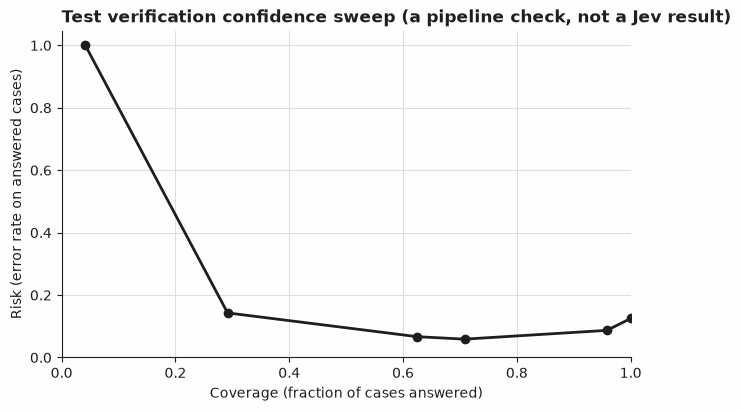

In [16]:
test_truth, test_noul = provisional_pairs(test_examples)
test_correct_verif = [
    (n >= business_threshold) == truth for n, truth in zip(test_noul, test_truth, strict=True)
]
test_confidence = noul_confidence(test_noul)
curve = selective_curve(test_correct_verif, test_confidence)
print(f"test verification confidence sweep, {len(test_truth)} pairs{check}:")
for i in range(len(curve.thresholds)):
    print(
        f"  gate {curve.thresholds[i]:.2f}: coverage {curve.coverage[i]:.4f}, "
        f"accuracy {curve.accuracy[i]:.4f}, risk {curve.risk[i]:.4f}{check}"
    )
plot_risk_coverage(curve, title=f"Test verification confidence sweep{check}")

In [17]:
print("Test fields the rule accepted but got wrong:")
for doc_id, field in test_keys:
    result = test_results[doc_id][field]
    gold_value = test_gold[doc_id][field]
    if result.outcome != helpers.REVIEW and not helpers.matches_gold(result, gold_value):
        print(
            f"  {doc_id}/{field}: outcome={result.outcome}, value={result.value!r}, "
            f"gold={gold_value!r}{check}"
        )

Test fields the rule accepted but got wrong:
  t04/invoice_number: outcome=extracted, value='Previous invoice reference 5998 was paid in full last month. ', gold='6004' (a pipeline check, not a Jev result)


Evaluation's own validation sweep, printed above, already lists a threshold that would have caught the error the cell above names: `validation threshold 0.86` scores `precision 1.0000 recall 0.7500 f1 0.8571`. The cell below freezes the business threshold at that value instead of `0.85` (the confidence gate unchanged) and recomputes both splits' field-level numbers, to show what using it would actually cost.


In [ ]:
alternate_business_threshold = 0.86


def field_results_at(split_examples, t):
    results = {}
    for example in split_examples:
        s1, a1, s2, a2 = decide(example)
        results[example.id] = {
            field: helpers.field_result(
                example.id, field, example.fields, a1, a2, t, confidence_gate
            )
            for field in helpers.FIELDS
        }
    return results


for split_name, split_examples, split_gold in (
    ("validation", val_examples, val_gold),
    ("test", test_examples, test_gold),
):
    at_alternate = field_results_at(split_examples, alternate_business_threshold)
    keys_alt, accepted_alt, correct_alt = helpers.flatten_fields(
        [e.id for e in split_examples], at_alternate, split_gold
    )
    report_alt = evaluate_outcomes(accepted_alt, correct_alt)
    print(
        f"{split_name} fields at business threshold {alternate_business_threshold:.2f}: "
        f"coverage {report_alt.coverage:.4f}, accuracy {report_alt.accuracy:.4f}, "
        f"risk {report_alt.risk:.4f}{check}"
    )

`t04`'s `invoice_number` -- the field "Test fields the rule accepted but got wrong" names earlier in this section -- names a decoy ("Previous invoice reference 5998 was paid in full last month") at stage 1, and stage 2's own verification confidently, wrongly agrees: confident enough to clear both the business threshold and the confidence gate. The cell immediately above shows that a threshold drawn from this very pool can still catch it: freezing the business threshold at `0.86` instead of `0.85` reaches accuracy `1.0000` and risk `0.0000` on both splits, with no accepted error left on either. What it costs is coverage -- `test`'s falls from `0.9286` to `0.7143` -- because the same cut-off also withholds every correct extraction whose own verification sits at exactly `0.85`. Catching the one confidently-wrong case this recipe's frozen rule misses is possible here; it is not free, and the fixtures are built to show that trade rather than average it away.


### How many requests this run made

`decide_calls`, set up next to `backend` above, counts every call to `backend.decide`, independent of the `decided` cache: a count that only reported how many distinct documents got cached would not have caught a document's cascade being decided twice. By this point every document in `fixtures/` -- `demo`, `validation`, and `test` alike -- has been decided exactly once, through that one shared cache, so this is also the exact number of requests a live run makes: the same number `fixtures/responses.json` stores a response for, and the same number the 'Switch to live' section budgets for.


In [ ]:
responses_count = len(json.loads(responses_path().read_text(encoding="utf-8")))
print(f"documents decided (distinct ids cached): {len(decided)}{check}")
print(f"backend.decide calls in this run: {decide_calls[0]}{check}")
print(f"stored responses in fixtures/responses.json: {responses_count}{check}")
assert decide_calls[0] == responses_count, (
    f"expected one decide() call per stored response ({responses_count}); made {decide_calls[0]}"
)

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the examples it covers. Nothing here says anything about Jev's quality, speed or cost unless that cell reports a recorded or live run. `N` below counts the scored documents; the field-level and task-level evaluations above cover all of them, just at two different granularities.


In [18]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test documents{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test documents")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 13 validation and 14 test documents (a pipeline check, not a Jev result)


## Next steps

- Change the wording of `_STAGE_1_INSTRUCTIONS["total_amount"]` in `helpers.py` and run `pytest recipes/39-document-extraction-cascade` or this notebook: the stored keys no longer match the question, so replay misses instead of guessing. `python build_fixtures.py` writes new keys but rewrites the committed fixtures; `git checkout recipes/39-document-extraction-cascade` restores them.
- Add a third field (a `due_date`, say) with its own extractor in `helpers.py`, and watch both the stage-1 and stage-2 requests grow by one question each, without the number of *requests* changing: the composition in `helpers.py` is written in terms of `FIELDS`, not a fixed pair.
- Neighbouring recipes: [`14-source-span-selection`](../14-source-span-selection/), whose single-stage `Choice`-over-spans pattern this recipe's own stage 1 reuses, and [`29-tool-outcome-verification`](../29-tool-outcome-verification/), another recipe whose second stage verifies what an earlier one produced.

A neighbour link above is a folder link, `../NN-slug/`: `tools/render_catalog.py` builds the root README's catalog table from bare recipe titles with no per-row anchor, so a recipe cannot reliably link to another recipe's row there instead. Both neighbours above are already published on `main`; a forward link to an unpublished recipe is not allowed ([docs/recipe-template.md](../../docs/recipe-template.md)).
